# PPO policies by alpha: Vanilla vs MaxMin

Line plots: x=alpha, y=positiveness, conciseness (divisor=256), minority score, majority score.

Could not load pcgrad alpha=0.75: At least one valid data file must be specified, all the data_files are invalid: {'train': []}


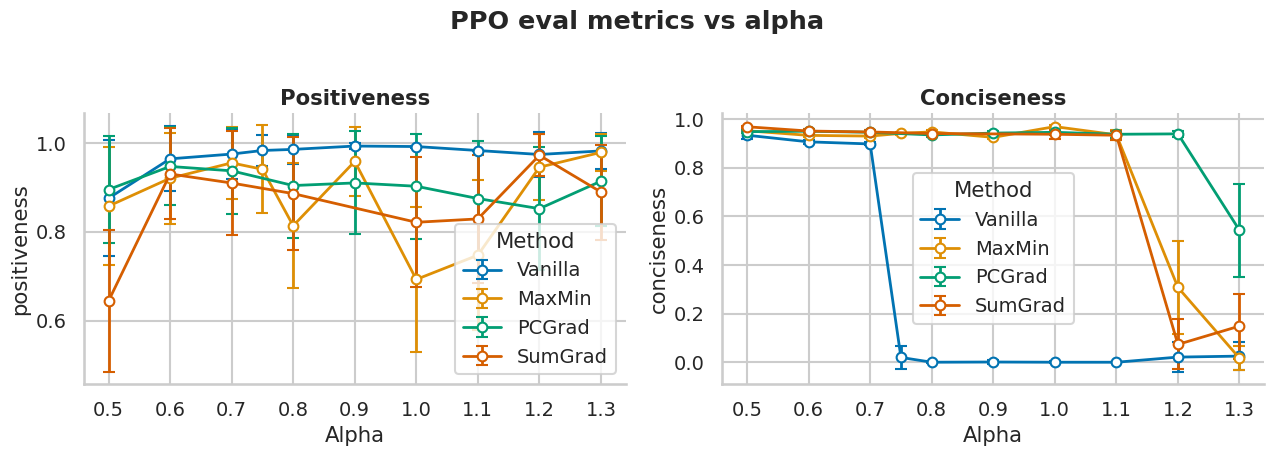

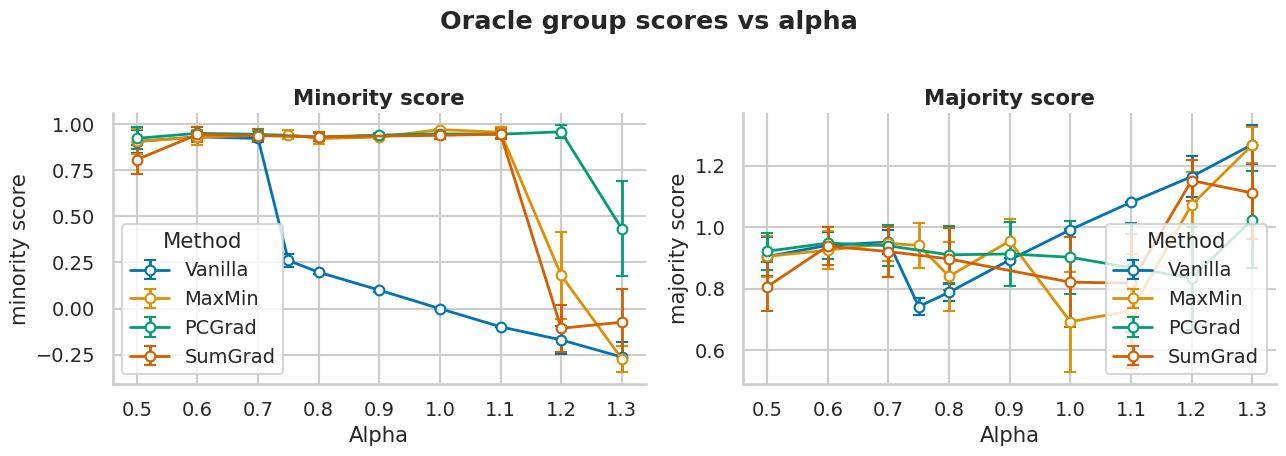

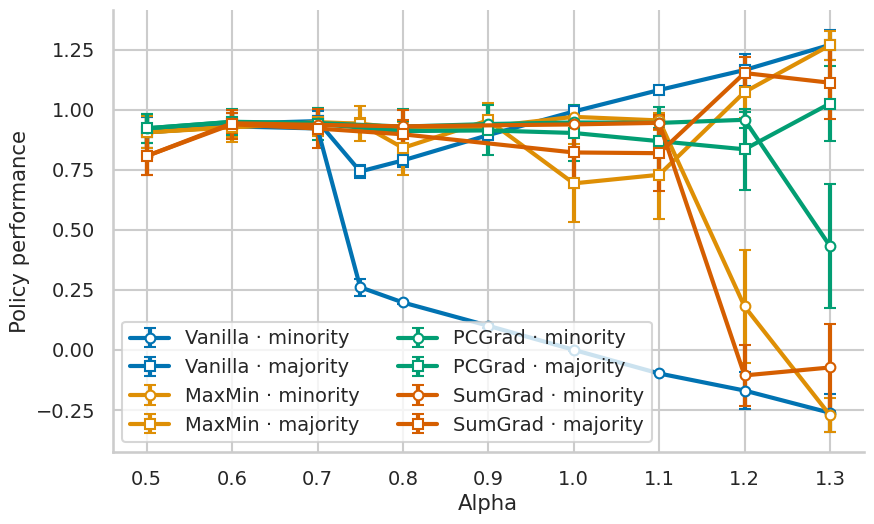

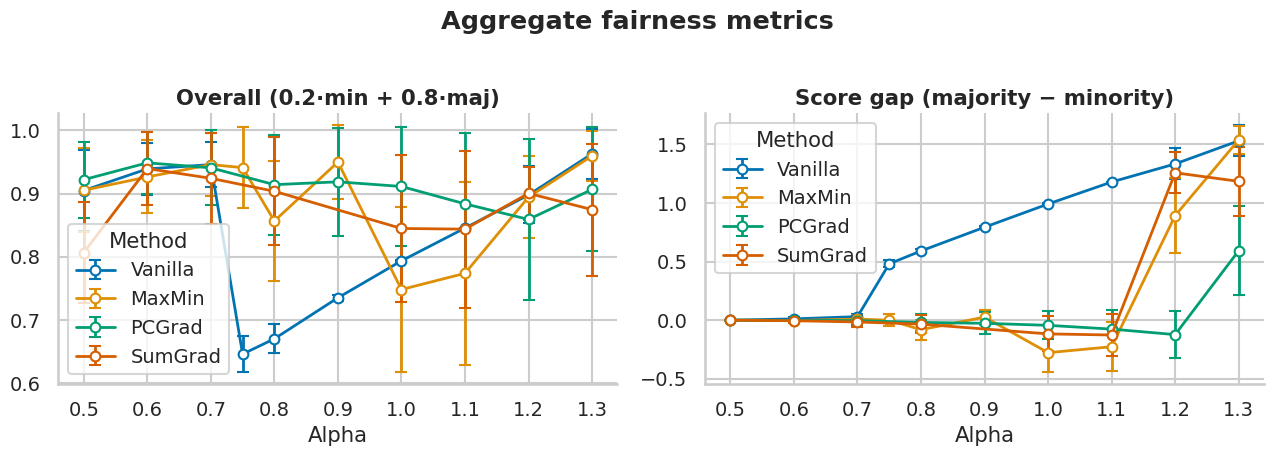

In [2]:
import sys
import os

ROOT = os.getcwd()
if not os.path.isdir(os.path.join(ROOT, "src")):
    ROOT = os.path.abspath(os.path.join(ROOT, ".."))
sys.path.insert(0, ROOT)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from src.helper.imdb_utils import load_ppo_eval

sns.set_theme(style="whitegrid", context="talk", palette="colorblind", font_scale=0.85)
METHOD_COLORS = {
    "vanilla": sns.color_palette("colorblind")[0],
    "maxmin": sns.color_palette("colorblind")[1],
    "pcgrad": sns.color_palette("colorblind")[2],
    "sumgrad": sns.color_palette("colorblind")[3],
}

USER_ID = "mxcui"
PPO_SEED = 43
PPO_PROPORTION = 0.2
DIVISOR = 256  # normalized_length = length / DIVISOR, conciseness = 1 - normalized_length

def _ppo_eval_id(method, alpha):
    if alpha == 0.5 and method == 'vanilla':
        return f"{USER_ID}/vanilla-imdb-ppo-eval-prop{PPO_PROPORTION}-alpha{alpha}-seed42-kl0.1-gpt2"
    elif method == "pcgrad":
        return f"{USER_ID}/pcgrad-imdb-ppo-eval-prop{PPO_PROPORTION}-alpha{alpha}-seed43"
    elif method == "sumgrad":
        return f"{USER_ID}/sumgrad-imdb-ppo-eval-prop{PPO_PROPORTION}-alpha{alpha}-seed42-mean_kl0.1-gpt2"
    else:
        return f"{USER_ID}/{method}-imdb-ppo-eval-prop{PPO_PROPORTION}-alpha{alpha}-seed{PPO_SEED}-mean_kl0.1-gpt2"

def oracle_minority(pos, nl, alpha):
    return (1 - nl) * alpha + (1 - alpha) * pos

def oracle_majority(pos, nl, alpha):
    return (1 - nl) * (1 - alpha) + alpha * pos

ALPHAS = [0.5, 0.6, 0.7, 0.75, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3]
results = {}

for alpha in ALPHAS:
    for method in ["vanilla", "maxmin", "pcgrad", "sumgrad"]:
        if alpha == 1.1 and method == "vanilla":
            continue  # interpolated from alpha 1.0 and 1.2 after the loop
        if method == "sumgrad" and alpha not in (0.5, 0.6, 0.7, 0.8, 1.0, 1.1, 1.2, 1.3):
            continue  # SumGrad trained for these alphas (seed42)
        try:
            ds_ppo = load_ppo_eval(_ppo_eval_id(method, alpha))
            df_ppo = ds_ppo.to_pandas()
        except Exception as e:
            print(f"Could not load {method} alpha={alpha}: {e}")
            continue
        if "positiveness" not in df_ppo.columns or "length" not in df_ppo.columns:
            if method == "pcgrad":
                # pcgrad eval datasets may exist but not yet be fully scored — skip silently
                print(f"Skipping {method} alpha={alpha}: dataset loaded but missing scored columns (not yet scored)")
                continue
            import torch
            from transformers import AutoTokenizer, AutoModelForSequenceClassification
            tokenizer = AutoTokenizer.from_pretrained("lvwerra/distilbert-imdb")
            model = AutoModelForSequenceClassification.from_pretrained("lvwerra/distilbert-imdb")
            model.eval()
            pos_id = model.config.label2id["POSITIVE"]
            pl, ll = [], []
            texts = df_ppo["completion"].astype(str).tolist()
            for i in range(0, len(texts), 64):
                enc = tokenizer(texts[i:i+64], padding=True, truncation=True, max_length=512, return_tensors="pt")
                with torch.no_grad():
                    probs = torch.softmax(model(**enc).logits, dim=-1)
                pl.extend(probs[:, pos_id].tolist())
                ll.extend(enc["attention_mask"].sum(dim=1).tolist())
            df_ppo["positiveness"], df_ppo["length"] = pl, ll
        df_ppo["normalized_length"] = np.clip(df_ppo["length"].astype(float) / DIVISOR, 0, 1)
        df_ppo["conciseness"] = 1 - df_ppo["normalized_length"]
        df_ppo["minority_score"] = oracle_minority(df_ppo["positiveness"], df_ppo["normalized_length"], alpha)
        df_ppo["majority_score"] = oracle_majority(df_ppo["positiveness"], df_ppo["normalized_length"], alpha)
        df_ppo["overall_performance"] = (
            PPO_PROPORTION * df_ppo["minority_score"]
            + (1 - PPO_PROPORTION) * df_ppo["majority_score"]
        )
        df_ppo["score_gap"] = df_ppo["majority_score"] - df_ppo["minority_score"]
        results[(alpha, method)] = df_ppo

# vanilla alpha=1.1: linear interp between 1.0 and 1.2 (no eval load)
_interp_alpha = 1.1
_lo, _hi = 1.0, 1.2
if (_lo, "vanilla") in results and (_hi, "vanilla") in results:
    t = (_interp_alpha - _lo) / (_hi - _lo)
    d0, d1 = results[(_lo, "vanilla")], results[(_hi, "vanilla")]
    df_ppo = pd.DataFrame({
        "positiveness": [(1 - t) * d0["positiveness"].mean() + t * d1["positiveness"].mean()],
        "length": [(1 - t) * d0["length"].mean() + t * d1["length"].mean()],
    })
    df_ppo["normalized_length"] = np.clip(df_ppo["length"].astype(float) / DIVISOR, 0, 1)
    df_ppo["conciseness"] = 1 - df_ppo["normalized_length"]
    df_ppo["minority_score"] = oracle_minority(
        df_ppo["positiveness"], df_ppo["normalized_length"], _interp_alpha
    )
    df_ppo["majority_score"] = oracle_majority(
        df_ppo["positiveness"], df_ppo["normalized_length"], _interp_alpha
    )
    df_ppo["overall_performance"] = (
        PPO_PROPORTION * df_ppo["minority_score"]
        + (1 - PPO_PROPORTION) * df_ppo["majority_score"]
    )
    df_ppo["score_gap"] = df_ppo["majority_score"] - df_ppo["minority_score"]
    results[(_interp_alpha, "vanilla")] = df_ppo

if not results:
    print("No PPO eval data loaded.")
else:
    metrics = [
        "positiveness", "conciseness", "minority_score", "majority_score",
        "overall_performance", "score_gap",
    ]
    rows = []
    for (a, m), d in results.items():
        row = {"alpha": a, "method": m}
        for metric in metrics:
            row[metric] = d[metric].mean()
            row[f"{metric}_std"] = d[metric].std()
        rows.append(row)
    df_agg = pd.DataFrame(rows)

    def _plot_by_method(ax, metric, title=None, ylabel=True):
        std_col = f"{metric}_std"
        for method in ["vanilla", "maxmin", "pcgrad", "sumgrad"]:
            sub = df_agg[df_agg["method"] == method].sort_values("alpha")
            if len(sub):
                yerr = 0.5 * sub[std_col].fillna(0)
                label = {"vanilla": "Vanilla", "maxmin": "MaxMin", "pcgrad": "PCGrad", "sumgrad": "SumGrad"}.get(method, method.capitalize())
                ax.errorbar(
                    sub["alpha"], sub[metric], yerr=yerr,
                    fmt="o-", label=label, capsize=4,
                    color=METHOD_COLORS[method], linewidth=2, markersize=7,
                    markerfacecolor="white", markeredgewidth=1.5,
                )
        ax.set_xlabel("Alpha")
        if ylabel:
            ax.set_ylabel(metric.replace("_", " "))
        if title is not None:
            ax.set_title(title, fontweight="semibold")
        ax.legend(title="Method", frameon=True)
        sns.despine(ax=ax)

    # 1. positiveness & conciseness
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    _plot_by_method(axes[0], "positiveness", title="Positiveness")
    _plot_by_method(axes[1], "conciseness", title="Conciseness")
    fig.suptitle("PPO eval metrics vs alpha", y=1.02, fontweight="semibold")
    plt.tight_layout()
    plt.show()

    # 2. minority & majority score
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    _plot_by_method(axes[0], "minority_score", title="Minority score")
    _plot_by_method(axes[1], "majority_score", title="Majority score")
    fig.suptitle("Oracle group scores vs alpha", y=1.02, fontweight="semibold")
    plt.tight_layout()
    plt.show()

    # 3. minority & majority on one plot
    fig, ax = plt.subplots(figsize=(9, 5.5))
    series = [
        ("vanilla", "minority_score", METHOD_COLORS["vanilla"], "o", "Vanilla · minority"),
        ("vanilla", "majority_score", METHOD_COLORS["vanilla"], "s", "Vanilla · majority"),
        ("maxmin", "minority_score", METHOD_COLORS["maxmin"], "o", "MaxMin · minority"),
        ("maxmin", "majority_score", METHOD_COLORS["maxmin"], "s", "MaxMin · majority"),
        ("pcgrad", "minority_score", METHOD_COLORS["pcgrad"], "o", "PCGrad · minority"),
        ("pcgrad", "majority_score", METHOD_COLORS["pcgrad"], "s", "PCGrad · majority"),
        ("sumgrad", "minority_score", METHOD_COLORS["sumgrad"], "o", "SumGrad · minority"),
        ("sumgrad", "majority_score", METHOD_COLORS["sumgrad"], "s", "SumGrad · majority"),
    ]
    for method, metric, color, marker, label in series:
        sub = df_agg[df_agg["method"] == method].sort_values("alpha")
        if len(sub):
            yerr = 0.5 * sub[f"{metric}_std"].fillna(0)
            ax.errorbar(
                sub["alpha"], sub[metric], yerr=yerr,
                fmt=f"{marker}-", color=color, label=label, capsize=4,
                linewidth=3, markersize=7, markerfacecolor="white", markeredgewidth=1.5,
            )
    ax.set_xlabel("Alpha")
    ax.set_ylabel("Policy performance")
    # ax.set_title("Minority vs majority scores", fontweight="semibold")
    ax.legend(frameon=True, ncol=2)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

    # 4. overall performance & score gap
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    _plot_by_method(
        axes[0], "overall_performance",
        title=f"Overall ({PPO_PROPORTION:.1f}·min + {1-PPO_PROPORTION:.1f}·maj)",
        ylabel=False,
    )
    _plot_by_method(axes[1], "score_gap", title="Score gap (majority − minority)", ylabel=False)
    fig.suptitle("Aggregate fairness metrics", y=1.02, fontweight="semibold")
    plt.tight_layout()
    plt.show()



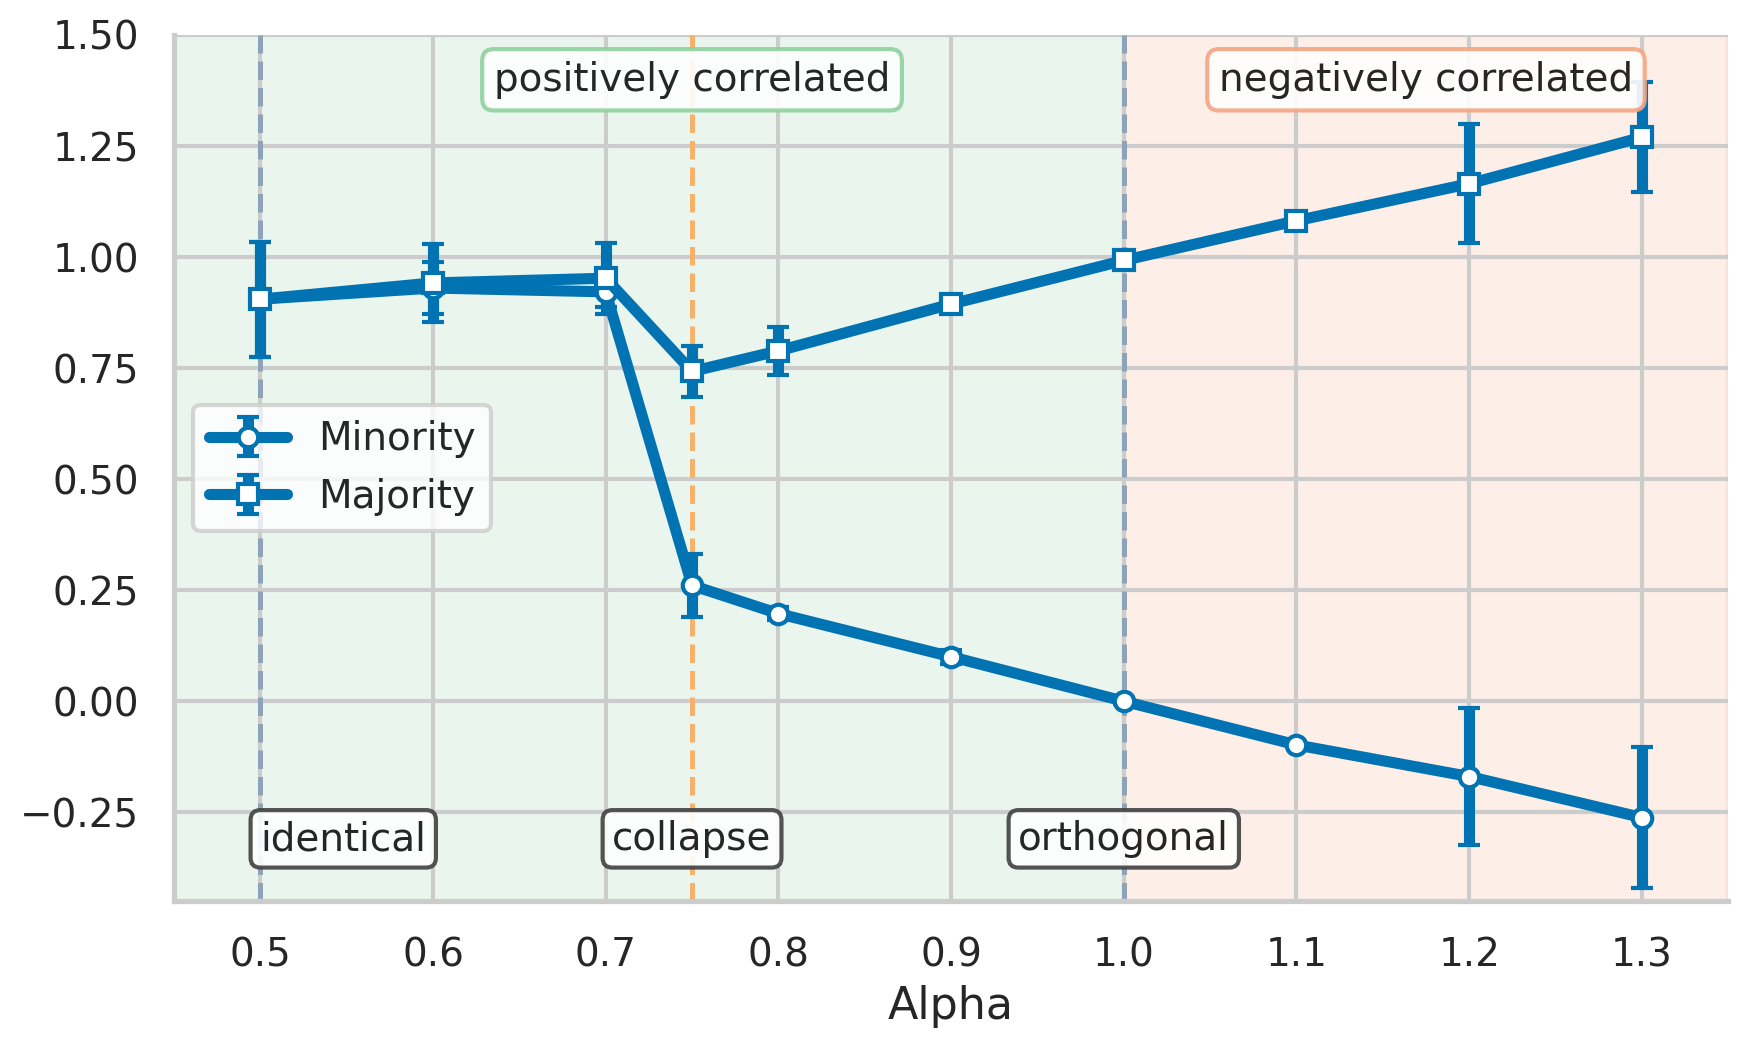

In [45]:
# Standalone minority/majority plot with alpha correlation regions
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=200)

ax.axvspan(0.45, 1.0, color="#8fd19e", alpha=0.18, zorder=0)
ax.axvspan(1.0, 1.35, color="#f4a582", alpha=0.18, zorder=0)
ax.axvline(0.5, color="#8FA3B8", linestyle="--", linewidth=1.8, zorder=1)
ax.axvline(0.75, color="#F6B26B", linestyle="--", linewidth=1.8, zorder=1)
ax.axvline(1.0, color="#8FA3B8", linestyle="--", linewidth=1.8, zorder=1)

series = [
    ("vanilla", "minority_score", METHOD_COLORS["vanilla"], "o", "Minority"),
    ("vanilla", "majority_score", METHOD_COLORS["vanilla"], "s", "Majority"),
    # ("maxmin", "minority_score", METHOD_COLORS["maxmin"], "o", "MaxMin - Min."),
    # ("maxmin", "majority_score", METHOD_COLORS["maxmin"], "s", "MaxMin - Maj."),
    # ("pcgrad", "minority_score", METHOD_COLORS["pcgrad"], "o", "PCGrad - Min."),
    # ("pcgrad", "majority_score", METHOD_COLORS["pcgrad"], "s", "PCGrad - Maj."),
]

for method, metric, color, marker, label in series:
    sub = df_agg[df_agg["method"] == method].sort_values("alpha")
    if len(sub):
        yerr = 1.0 * sub[f"{metric}_std"].fillna(0)
        ax.errorbar(
            sub["alpha"], sub[metric], yerr=yerr,
            fmt=f"{marker}-", color=color, label=label, capsize=4,
            linewidth=4, markersize=7, markerfacecolor="white", markeredgewidth=1.5,
            zorder=2,
        )

ax.text(
    0.75, 0.97, "positively correlated", fontsize=14,
    transform=ax.get_xaxis_transform(), ha="center", va="top", zorder=3,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#8fd19e", "alpha": 0.9},
)
ax.text(
    1.175, 0.97, "negatively correlated", fontsize=14,
    transform=ax.get_xaxis_transform(), ha="center", va="top", zorder=3,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#f4a582", "alpha": 0.9},
)
ax.text(
    0.5, 0.05, "identical", fontsize=14,
    transform=ax.get_xaxis_transform(), ha="left", va="bottom", rotation=0, zorder=3,
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "0.25", "alpha": 0.9},
)
ax.text(
    1.0, 0.05, "orthogonal", fontsize=14,
    transform=ax.get_xaxis_transform(), ha="center", va="bottom", rotation=0, zorder=3,
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "0.25", "alpha": 0.9},
)

ax.text(
    0.75, 0.05, "collapse", fontsize=14,
    transform=ax.get_xaxis_transform(), ha="center", va="bottom", rotation=0, zorder=3,
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "0.25", "alpha": 0.9},
)

ax.set_xlim(0.45, 1.35)
ax.set_ylim(-0.45, 1.5)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3])
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_xlabel("Alpha", fontsize=16)
# ax.set_ylabel("Policy performance")
ax.legend(frameon=True, loc="center left", ncol=1, fontsize=14)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("ppo_by_alpha_vanilla.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()

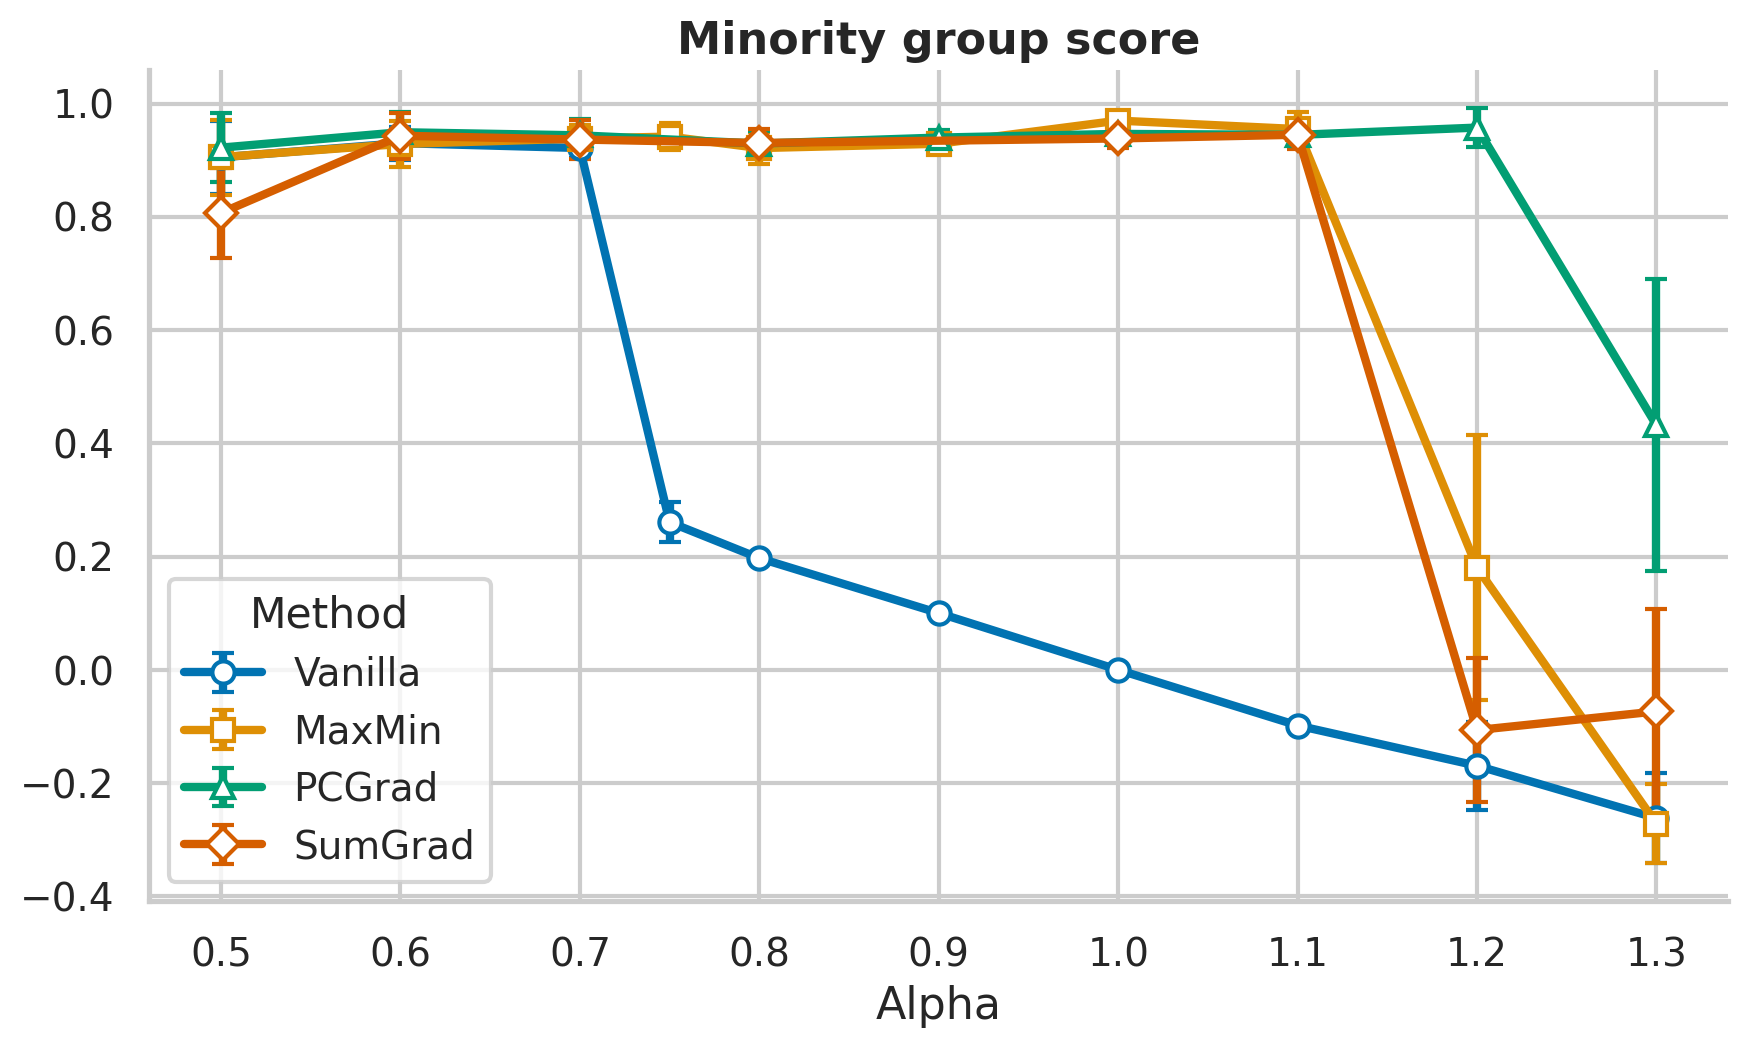

In [4]:
# Standalone minority score plot
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=200)

method_labels = {"vanilla": "Vanilla", "maxmin": "MaxMin", "pcgrad": "PCGrad", "sumgrad": "SumGrad"}
method_markers = {"vanilla": "o", "maxmin": "s", "pcgrad": "^", "sumgrad": "D"}

for method in ["vanilla", "maxmin", "pcgrad", "sumgrad"]:
    sub = df_agg[df_agg["method"] == method].sort_values("alpha")
    if len(sub):
        yerr = 0.5 * sub["minority_score_std"].fillna(0)
        ax.errorbar(
            sub["alpha"], sub["minority_score"], yerr=yerr,
            fmt=f"{method_markers[method]}-", color=METHOD_COLORS[method],
            label=method_labels[method], capsize=4,
            linewidth=3, markersize=8, markerfacecolor="white", markeredgewidth=1.5,
        )

ax.set_xlabel("Alpha", fontsize=16)
# ax.set_ylabel("Minority score")
ax.set_title("Minority group score", fontweight="semibold", fontsize=16)
ax.legend(title="Method", frameon=True)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("../images/with_sumgrad/ppo_by_alpha_minority.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


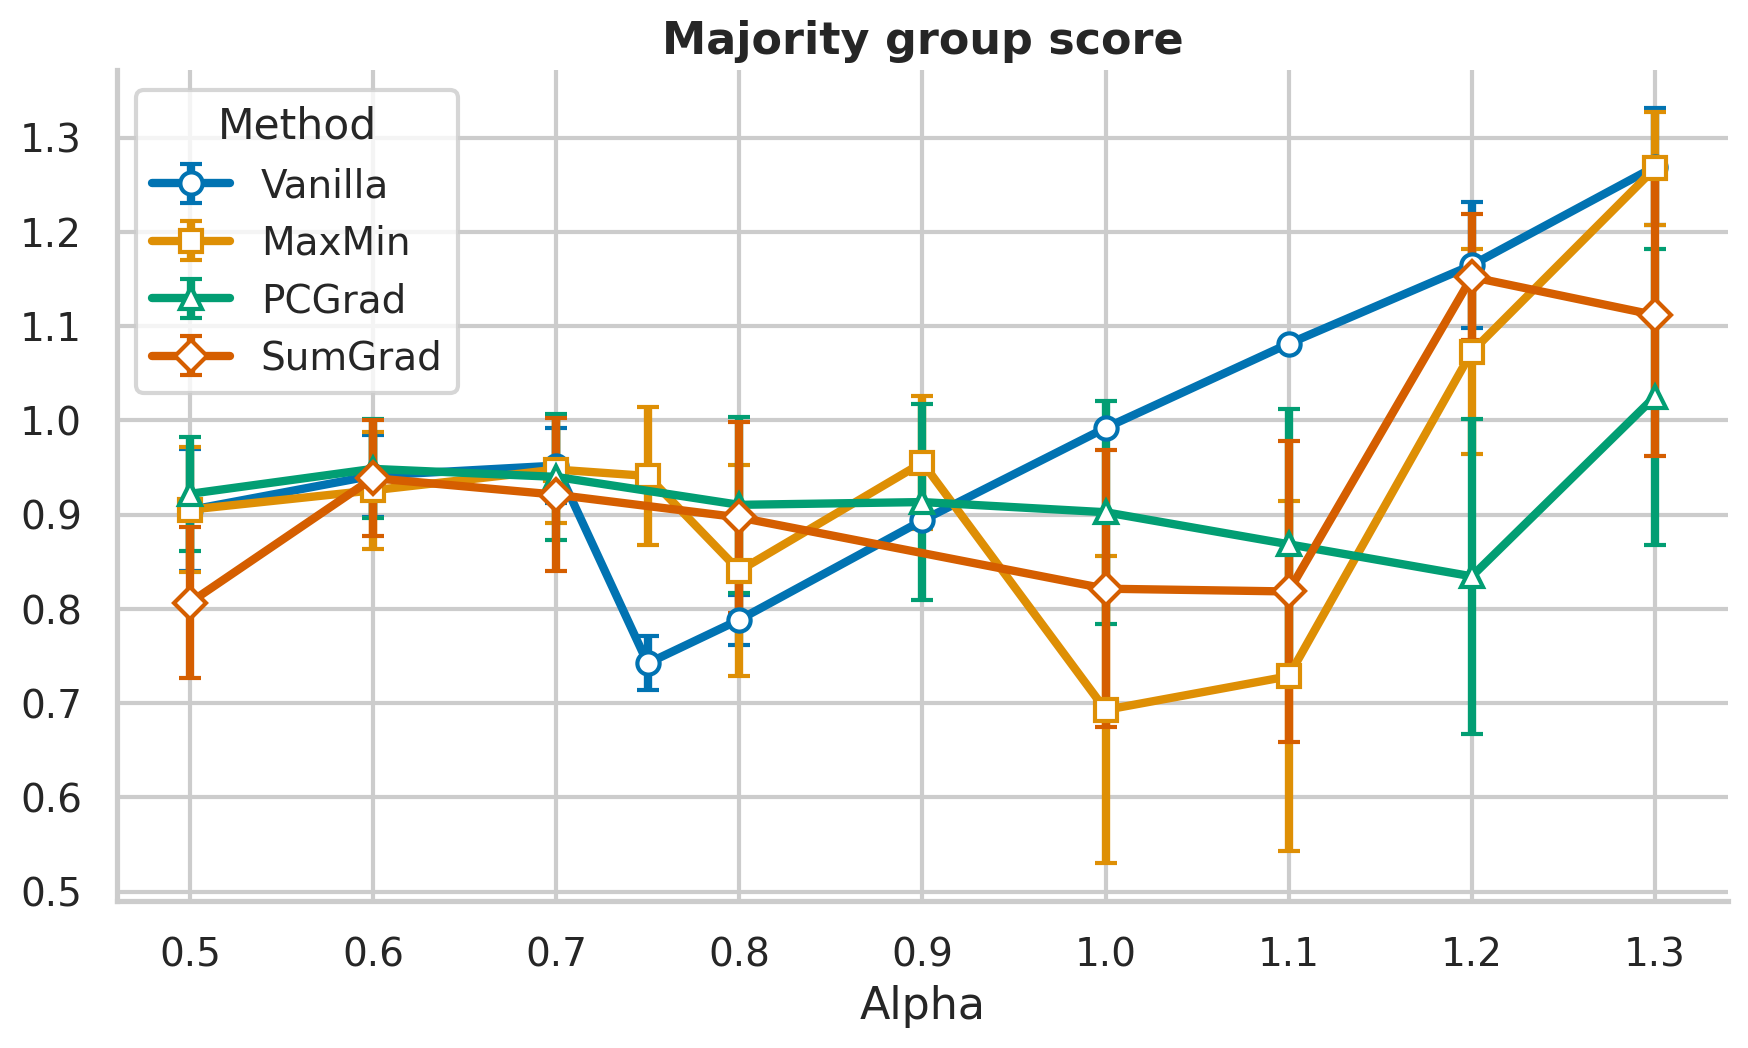

In [5]:
# Standalone majority score plot
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=200)

method_labels = {"vanilla": "Vanilla", "maxmin": "MaxMin", "pcgrad": "PCGrad", "sumgrad": "SumGrad"}
method_markers = {"vanilla": "o", "maxmin": "s", "pcgrad": "^", "sumgrad": "D"}

for method in ["vanilla", "maxmin", "pcgrad", "sumgrad"]:
    sub = df_agg[df_agg["method"] == method].sort_values("alpha")
    if len(sub):
        yerr = 0.5 * sub["majority_score_std"].fillna(0)
        ax.errorbar(
            sub["alpha"], sub["majority_score"], yerr=yerr,
            fmt=f"{method_markers[method]}-", color=METHOD_COLORS[method],
            label=method_labels[method], capsize=4,
            linewidth=3, markersize=8, markerfacecolor="white", markeredgewidth=1.5,
        )

ax.set_xlabel("Alpha", fontsize=16)
# ax.set_ylabel("Majority score")
ax.set_title("Majority group score", fontweight="semibold", fontsize=16)
ax.legend(title="Method", frameon=True)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("../images/with_sumgrad/ppo_by_alpha_majority.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


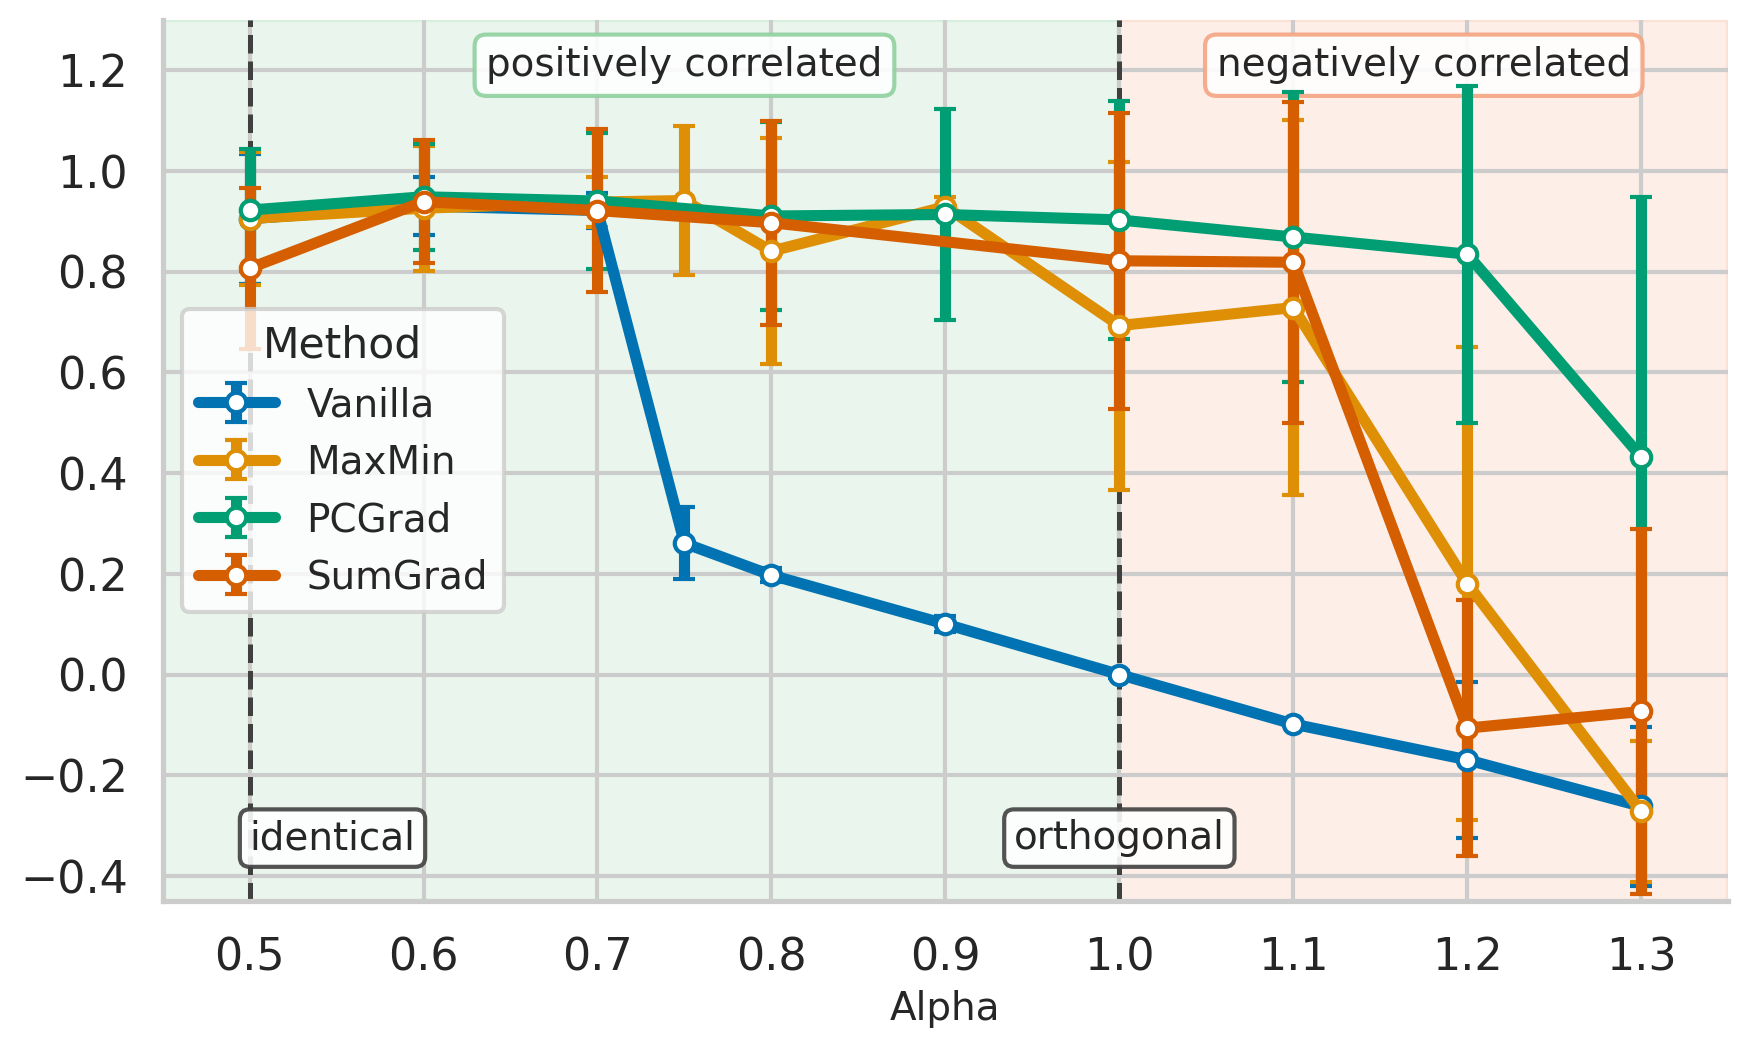

In [6]:
# Worst group score across methods
method_labels = {"vanilla": "Vanilla", "maxmin": "MaxMin", "pcgrad": "PCGrad", "sumgrad": "SumGrad"}

df_worst = df_agg.copy()
df_worst["worst_group_score"] = df_worst[["minority_score", "majority_score"]].min(axis=1)
df_worst["worst_group"] = np.where(
    df_worst["minority_score"] <= df_worst["majority_score"],
    "minority",
    "majority",
)
df_worst["worst_group_std"] = np.where(
    df_worst["worst_group"] == "minority",
    df_worst["minority_score_std"],
    df_worst["majority_score_std"],
)

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=200)

ax.axvspan(0.45, 1.0, color="#8fd19e", alpha=0.18, zorder=0)
ax.axvspan(1.0, 1.35, color="#f4a582", alpha=0.18, zorder=0)
ax.axvline(0.5, color="0.25", linestyle="--", linewidth=1.8, zorder=1)
ax.axvline(1.0, color="0.25", linestyle="--", linewidth=1.8, zorder=1)

for method in ["vanilla", "maxmin", "pcgrad", "sumgrad"]:
    sub = df_worst[df_worst["method"] == method].sort_values("alpha")
    if len(sub):
        yerr = 1.0 * pd.Series(sub["worst_group_std"]).fillna(0)
        ax.errorbar(
            sub["alpha"], sub["worst_group_score"], yerr=yerr,
            fmt="o-", color=METHOD_COLORS[method], label=method_labels[method], capsize=4,
            linewidth=4, markersize=7, markerfacecolor="white", markeredgewidth=1.5,
            zorder=3,
        )

ax.text(
    0.75, 0.97, "positively correlated", fontsize=14,
    transform=ax.get_xaxis_transform(), ha="center", va="top", zorder=2,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#8fd19e", "alpha": 0.9},
)
ax.text(
    1.175, 0.97, "negatively correlated", fontsize=14,
    transform=ax.get_xaxis_transform(), ha="center", va="top", zorder=2,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#f4a582", "alpha": 0.9},
)
ax.text(
    0.5, 0.05, "identical", fontsize=14,
    transform=ax.get_xaxis_transform(), ha="left", va="bottom", rotation=0, zorder=2,
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "0.25", "alpha": 0.9},
)
ax.text(
    1.0, 0.05, "orthogonal", fontsize=14,
    transform=ax.get_xaxis_transform(), ha="center", va="bottom", rotation=0, zorder=2,
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "0.25", "alpha": 0.9},
)

ax.set_xlim(0.45, 1.35)
ax.set_ylim(-0.45, 1.3)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3])
ax.tick_params(axis='both', which='major', labelsize=16)
ax.set_xlabel("Alpha", fontsize=14)
# ax.set_title("Worst group score", fontsize=16)
ax.legend(title="Method", frameon=True, loc="center left", fontsize=14)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("../images/with_sumgrad/ppo_by_alpha_worst.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()

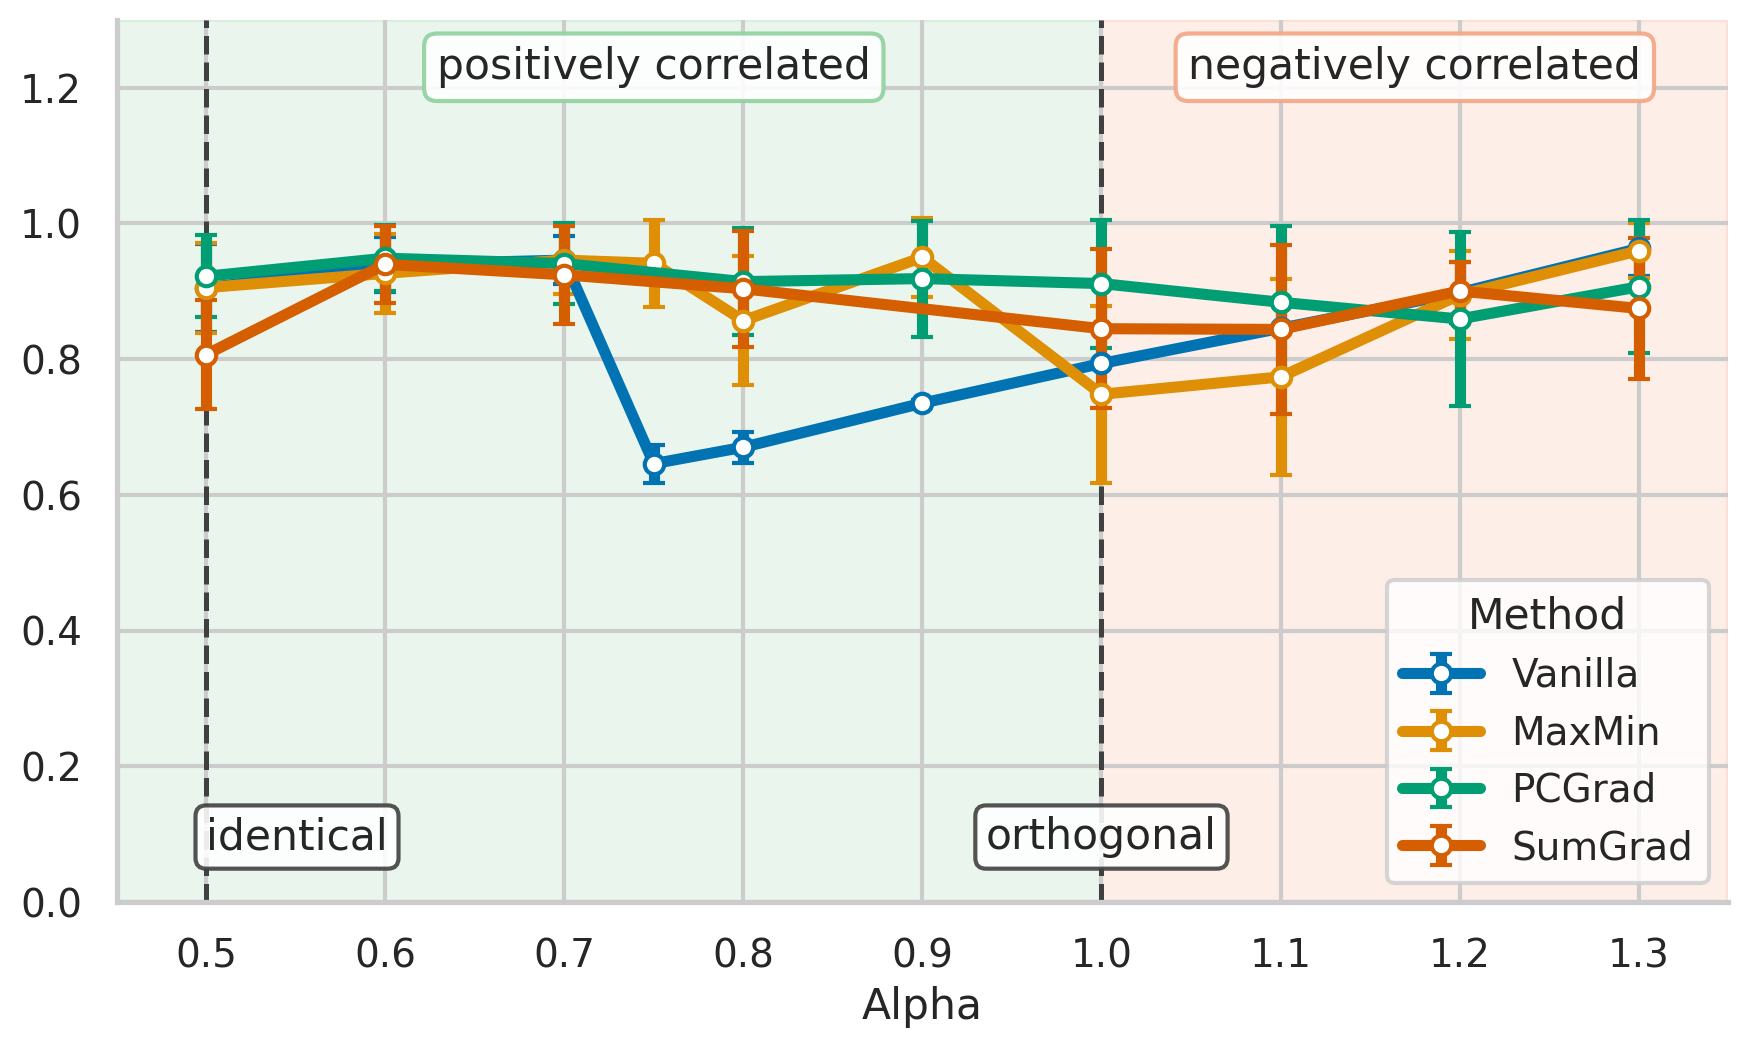

In [7]:
# Overall performance across methods
method_labels = {"vanilla": "Vanilla", "maxmin": "MaxMin", "pcgrad": "PCGrad", "sumgrad": "SumGrad"}

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=200)

ax.axvspan(0.45, 1.0, color="#8fd19e", alpha=0.18, zorder=0)
ax.axvspan(1.0, 1.35, color="#f4a582", alpha=0.18, zorder=0)
ax.axvline(0.5, color="0.25", linestyle="--", linewidth=1.8, zorder=1)
ax.axvline(1.0, color="0.25", linestyle="--", linewidth=1.8, zorder=1)

for method in ["vanilla", "maxmin", "pcgrad", "sumgrad"]:
    sub = df_agg[df_agg["method"] == method].sort_values("alpha")
    if len(sub):
        yerr = 0.5 * sub["overall_performance_std"].fillna(0)
        ax.errorbar(
            sub["alpha"], sub["overall_performance"], yerr=yerr,
            fmt="o-", color=METHOD_COLORS[method], label=method_labels[method], capsize=4,
            linewidth=4, markersize=7, markerfacecolor="white", markeredgewidth=1.5,
            zorder=2,
        )

ax.text(
    0.75, 0.97, "positively correlated",
    transform=ax.get_xaxis_transform(), ha="center", va="top", zorder=3,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#8fd19e", "alpha": 0.9},
)
ax.text(
    1.175, 0.97, "negatively correlated",
    transform=ax.get_xaxis_transform(), ha="center", va="top", zorder=3,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#f4a582", "alpha": 0.9},
)
ax.text(
    0.5, 0.05, "identical",
    transform=ax.get_xaxis_transform(), ha="left", va="bottom", rotation=0, zorder=3,
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "0.25", "alpha": 0.9},
)
ax.text(
    1.0, 0.05, "orthogonal",
    transform=ax.get_xaxis_transform(), ha="center", va="bottom", rotation=0, zorder=3,
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "0.25", "alpha": 0.9},
)

ax.set_xlim(0.45, 1.35)
ax.set_ylim(0, 1.3)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3])
ax.set_xlabel("Alpha")
# ax.set_ylabel(f"Overall performance ({PPO_PROPORTION:.1f} min + {1-PPO_PROPORTION:.1f} maj)")
ax.legend(title="Method", frameon=True, loc="best")
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("../images/with_sumgrad/ppo_by_alpha_overall.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()

In [ ]:
# Pearson correlation between minority and majority rewards vs alpha
# r_min = alpha*c + (1-alpha)*pos,  r_maj = (1-alpha)*c + alpha*pos
# Use vanilla data pooled across all loaded alphas as the reference distribution.
# Estimate cov(c, pos), var(c), var(pos) once; then sweep alpha analytically.

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- pool raw (positiveness, conciseness) from vanilla runs ---
pos_all, c_all = [], []
for (a, m), df in results.items():
    if m == "vanilla" and "positiveness" in df.columns and "normalized_length" in df.columns:
        pos_all.append(df["positiveness"].values)
        c_all.append(1.0 - np.clip(df["normalized_length"].values, 0, 1))

if not pos_all:
    raise RuntimeError("No vanilla data found in `results`.")

pos_pool = np.concatenate(pos_all)
c_pool   = np.concatenate(c_all)

var_pos = np.var(pos_pool, ddof=1)
var_c   = np.var(c_pool,   ddof=1)
cov_pc  = np.cov(pos_pool, c_pool, ddof=1)[0, 1]

# --- analytical Pearson sweep ---
alphas_dense = np.linspace(0.48, 1.35, 500)

def pearson_rewards(a, var_pos, var_c, cov_pc):
    # Cov(r_min, r_maj)  =  a(1-a)(var_c + var_pos) + (a^2 + (1-a)^2) * cov_pc
    cov_rr = a * (1 - a) * (var_c + var_pos) + (a**2 + (1 - a)**2) * cov_pc
    # Var(r_min) = a^2 var_c + (1-a)^2 var_pos + 2a(1-a) cov_pc
    var_min = a**2 * var_c + (1 - a)**2 * var_pos + 2 * a * (1 - a) * cov_pc
    # Var(r_maj) = (1-a)^2 var_c + a^2 var_pos + 2a(1-a) cov_pc
    var_maj = (1 - a)**2 * var_c + a**2 * var_pos + 2 * a * (1 - a) * cov_pc
    denom = np.sqrt(np.maximum(var_min, 0) * np.maximum(var_maj, 0))
    return np.where(denom > 0, cov_rr / denom, 0.0)

pearson_vals = pearson_rewards(alphas_dense, var_pos, var_c, cov_pc)

# --- plot ---
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)

ax.axhline(0, color="gray", linestyle=":", linewidth=1.2, zorder=0)
ax.axvspan(0.48, 1.0, color="#8fd19e", alpha=0.15, zorder=0, label="_pos region")
ax.axvspan(1.0, 1.35, color="#f4a582", alpha=0.15, zorder=0, label="_neg region")

ax.plot(alphas_dense, pearson_vals, color="steelblue", linewidth=2.5, zorder=3)

# reference verticals
ax.axvline(0.5,  color="#8FA3B8", linestyle="--", linewidth=1.5, zorder=2)
ax.axvline(1.0,  color="#8FA3B8", linestyle="--", linewidth=1.5, zorder=2)

# annotations
trans = ax.get_xaxis_transform()
ax.text(0.75, 0.96, "positively correlated", fontsize=11,
        transform=trans, ha="center", va="top", zorder=4,
        bbox={"boxstyle": "round,pad=0.3", "facecolor": "white",
              "edgecolor": "#8fd19e", "alpha": 0.9})
ax.text(1.175, 0.96, "negatively correlated", fontsize=11,
        transform=trans, ha="center", va="top", zorder=4,
        bbox={"boxstyle": "round,pad=0.3", "facecolor": "white",
              "edgecolor": "#f4a582", "alpha": 0.9})
ax.text(0.5, 0.06, "identical\nrewards", fontsize=10,
        transform=trans, ha="left", va="bottom", zorder=4,
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white",
              "edgecolor": "0.4", "alpha": 0.9})
ax.text(1.0, 0.06, "orthogonal", fontsize=10,
        transform=trans, ha="center", va="bottom", zorder=4,
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white",
              "edgecolor": "0.4", "alpha": 0.9})

ax.set_xlim(0.48, 1.35)
ax.set_xlabel(r"$\alpha$", fontsize=14)
ax.set_ylabel("Pearson($r_\mathrm{min}$, $r_\mathrm{maj}$)", fontsize=13)
ax.set_title("Correlation between group rewards vs $\\alpha$", fontweight="semibold")
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("pearson_vs_alpha.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()

print(f"Pearson at α=0.5 : {pearson_rewards(0.5,  var_pos, var_c, cov_pc):.4f}  (should be ≈1)")
print(f"Pearson at α=1.0 : {pearson_rewards(1.0,  var_pos, var_c, cov_pc):.4f}  (= Pearson(c, pos))")
print(f"Pearson at α=1.3 : {pearson_rewards(1.3,  var_pos, var_c, cov_pc):.4f}")


Using W&B directory: /workspace/fairness-rlhf/wandb


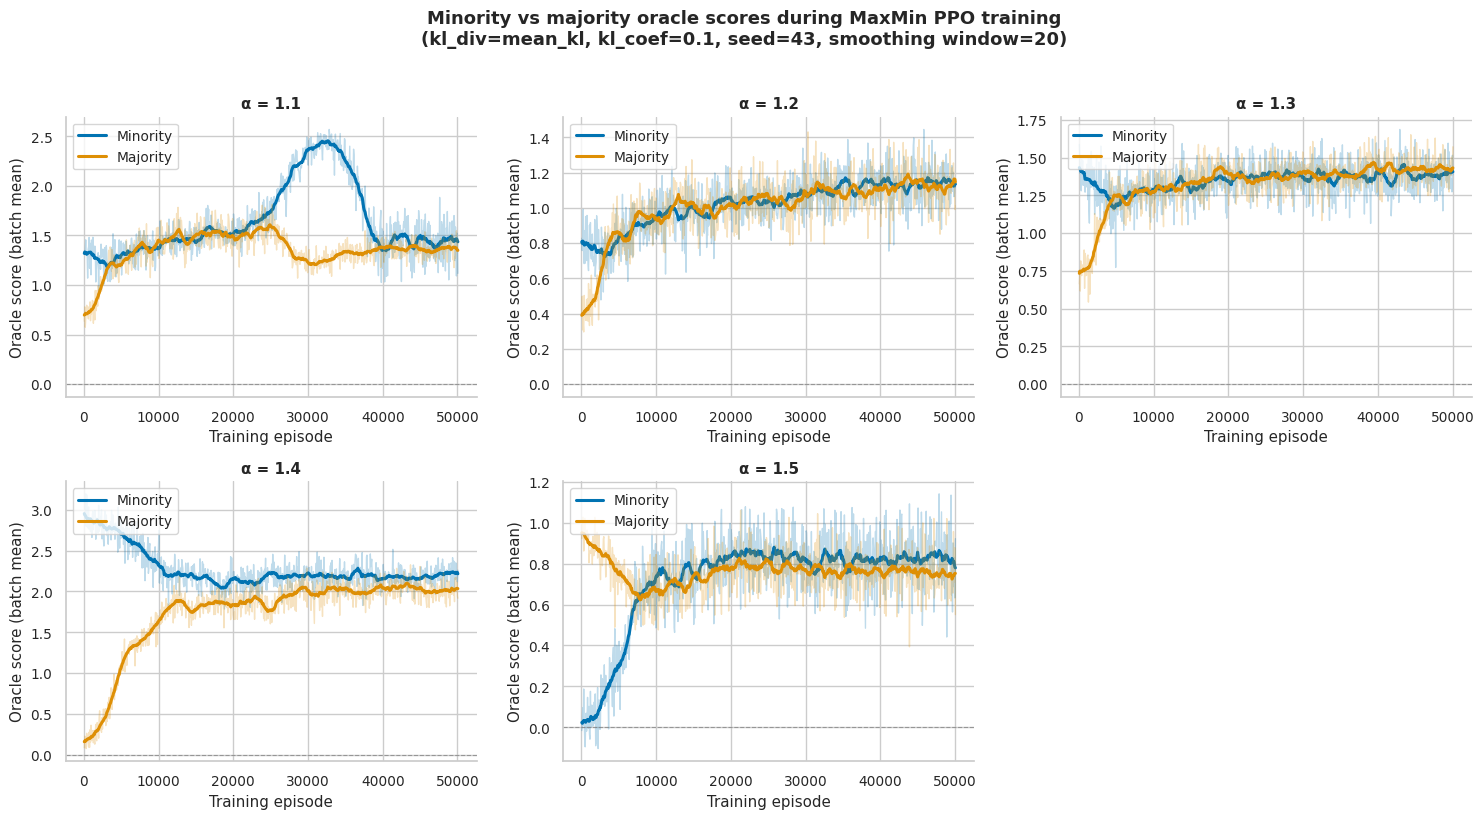

In [12]:
import ast
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind", font_scale=0.9)
MINORITY_COLOR = sns.color_palette("colorblind")[0]
MAJORITY_COLOR = sns.color_palette("colorblind")[1]

ROOT = os.getcwd()
if not os.path.isdir(os.path.join(ROOT, "wandb")) and os.path.isdir(os.path.join(ROOT, "..", "wandb")):
    ROOT = os.path.abspath(os.path.join(ROOT, ".."))
WANDB_DIR = os.path.join(ROOT, "wandb")
print(f"Using W&B directory: {WANDB_DIR}")

# Local MaxMin PPO/RLHF runs with kl_div=mean_kl, kl_coef=0.1, seed=43
MAXMIN_RUNS = {
    1.1: "run-20260522_225122-5v1w8llb",
    1.2: "run-20260522_225157-5yyzko1m",
    1.3: "run-20260522_062456-pkok27l6",
    1.4: "run-20260522_062510-hzjpf0lz",
    1.5: "run-20260521_071421-0apkfhnw",
}

def parse_group_scores(log_path):
    records = []
    with open(log_path) as f:
        for line in f:
            line = line.strip()
            if "group_selection/mean_reward_minority" not in line:
                continue
            try:
                d = ast.literal_eval(line)
                records.append({
                    "episode": int(d["episode"]),
                    "minority": float(d["group_selection/mean_reward_minority"]),
                    "majority": float(d["group_selection/mean_reward_majority"]),
                    "worst_group": d.get("group_selection/worst_group_name", ""),
                })
            except Exception:
                pass
    return pd.DataFrame(records)

SMOOTH_WINDOW = 20

alphas = sorted(MAXMIN_RUNS.keys())
ncols = 3
nrows = (len(alphas) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows), sharey=False)
axes = axes.flatten()

for ax, alpha in zip(axes, alphas):
    run_name = MAXMIN_RUNS[alpha]
    log_path = os.path.join(WANDB_DIR, run_name, "files", "output.log")
    if not os.path.isfile(log_path):
        print(f"Missing log for alpha={alpha}: {log_path}")
        ax.axis("off")
        continue

    df = parse_group_scores(log_path)
    if df.empty:
        print(f"No group score records found for alpha={alpha}: {log_path}")
        ax.axis("off")
        continue

    df = df.sort_values("episode").reset_index(drop=True)
    df["minority_smooth"] = df["minority"].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean()
    df["majority_smooth"] = df["majority"].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean()

    sns.lineplot(
        data=df, x="episode", y="minority", ax=ax,
        color=MINORITY_COLOR, alpha=0.25, linewidth=1, legend=False,
    )
    sns.lineplot(
        data=df, x="episode", y="minority_smooth", ax=ax,
        color=MINORITY_COLOR, linewidth=2.2, label="Minority",
    )
    sns.lineplot(
        data=df, x="episode", y="majority", ax=ax,
        color=MAJORITY_COLOR, alpha=0.25, linewidth=1, legend=False,
    )
    sns.lineplot(
        data=df, x="episode", y="majority_smooth", ax=ax,
        color=MAJORITY_COLOR, linewidth=2.2, label="Majority",
    )
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
    ax.set_xlabel("Training episode")
    ax.set_ylabel("Oracle score (batch mean)")
    ax.set_title(f"α = {alpha}", fontweight="semibold")
    ax.legend(loc="upper left", frameon=True)
    sns.despine(ax=ax)

for ax in axes[len(alphas):]:
    ax.set_visible(False)

fig.suptitle(
    f"Minority vs majority oracle scores during MaxMin PPO training\n"
    f"(kl_div=mean_kl, kl_coef=0.1, seed=43, smoothing window={SMOOTH_WINDOW})",
    y=1.02, fontweight="semibold",
)
plt.tight_layout()
plt.show()

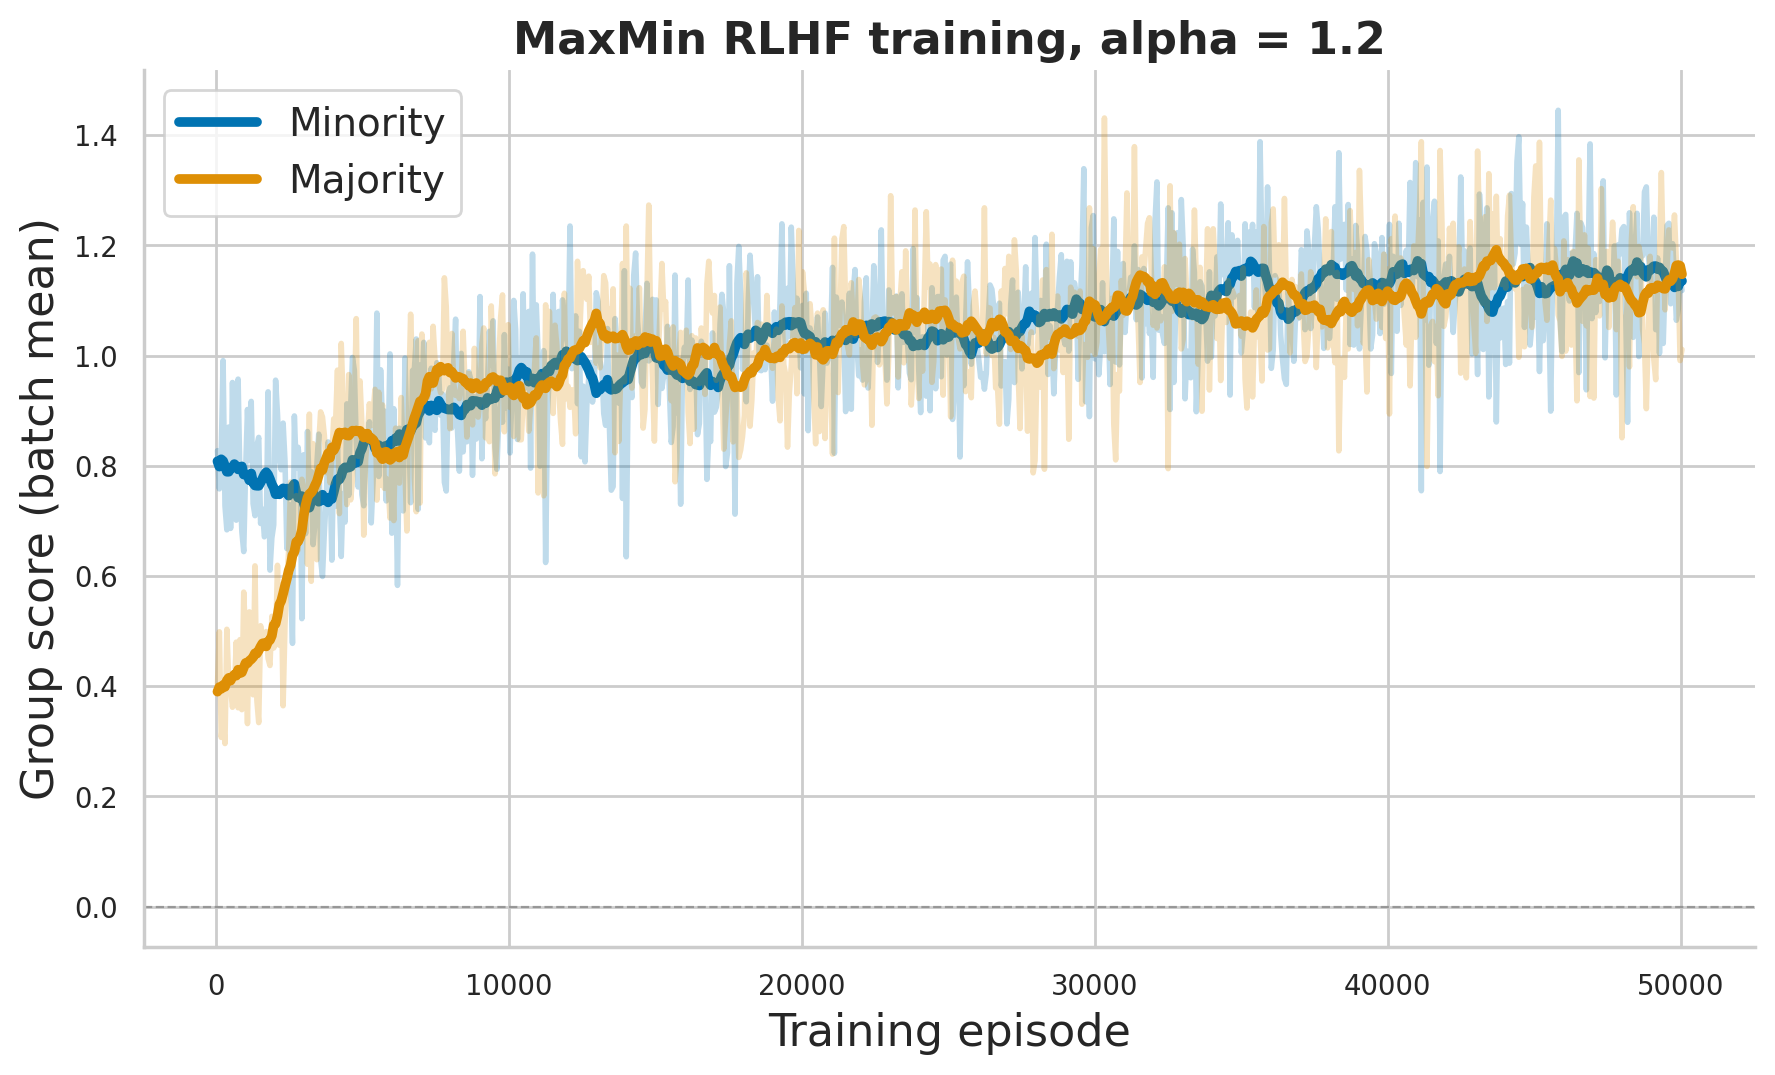

In [20]:
# Single MaxMin PPO training plot: alpha = 1.2
alpha = 1.2
run_name = MAXMIN_RUNS[alpha]
log_path = os.path.join(WANDB_DIR, run_name, "files", "output.log")

df = parse_group_scores(log_path).sort_values("episode").reset_index(drop=True)
df["minority_smooth"] = df["minority"].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean()
df["majority_smooth"] = df["majority"].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean()

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=200)
sns.lineplot(
    data=df, x="episode", y="minority", ax=ax,
    color=MINORITY_COLOR, alpha=0.25, linewidth=2, legend=False,
)
sns.lineplot(
    data=df, x="episode", y="minority_smooth", ax=ax,
    color=MINORITY_COLOR, linewidth=3.5, label="Minority",
)
sns.lineplot(
    data=df, x="episode", y="majority", ax=ax,
    color=MAJORITY_COLOR, alpha=0.25, linewidth=2, legend=False,
)
sns.lineplot(
    data=df, x="episode", y="majority_smooth", ax=ax,
    color=MAJORITY_COLOR, linewidth=3.5, label="Majority",
)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax.set_xlabel("Training episode", fontsize=16)
ax.set_ylabel("Group score (batch mean)", fontsize=16)
ax.set_title(f"MaxMin RLHF training, alpha = {alpha}", fontweight="semibold", fontsize=16)
ax.legend(loc="upper left", frameon=True, fontsize=14)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("ppo_by_alpha_maxmin_1.2.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


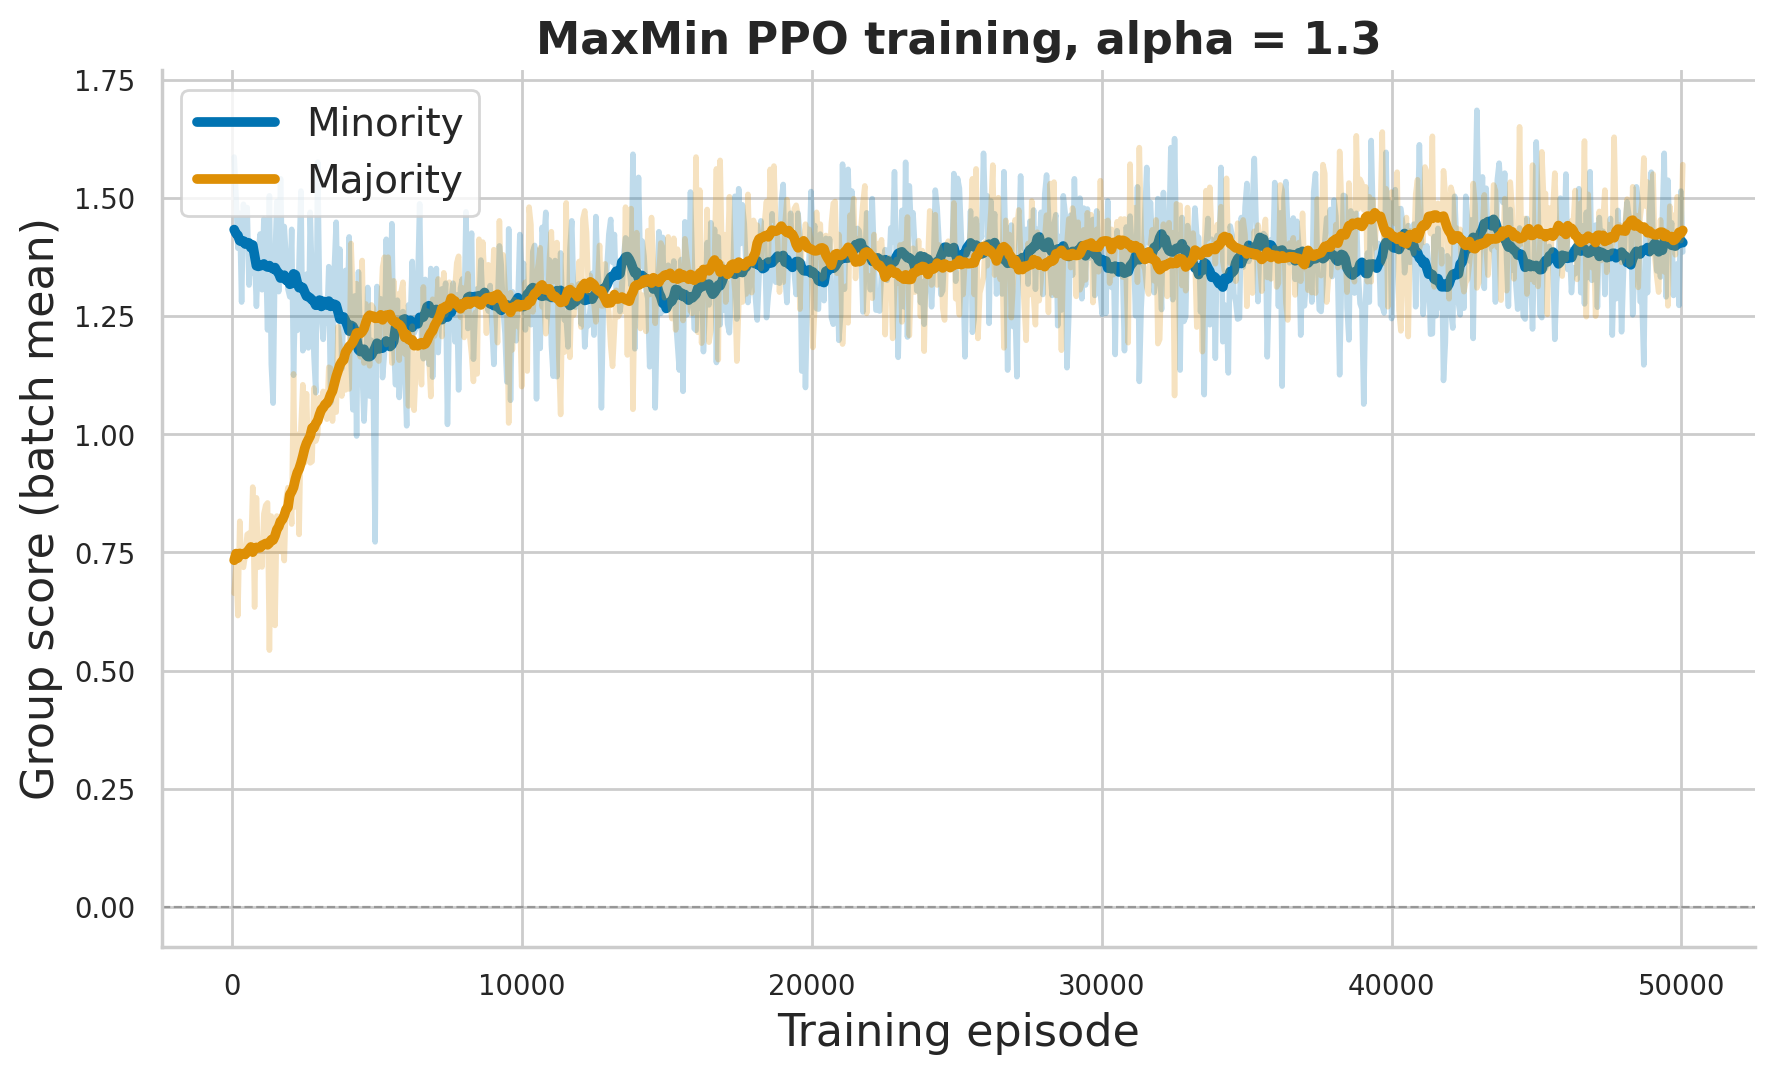

In [19]:
# Single MaxMin PPO training plot: alpha = 1.3
alpha = 1.3
run_name = MAXMIN_RUNS[alpha]
log_path = os.path.join(WANDB_DIR, run_name, "files", "output.log")

df = parse_group_scores(log_path).sort_values("episode").reset_index(drop=True)
df["minority_smooth"] = df["minority"].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean()
df["majority_smooth"] = df["majority"].rolling(SMOOTH_WINDOW, min_periods=1, center=True).mean()

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=200)
sns.lineplot(
    data=df, x="episode", y="minority", ax=ax,
    color=MINORITY_COLOR, alpha=0.25, linewidth=2, legend=False,
)
sns.lineplot(
    data=df, x="episode", y="minority_smooth", ax=ax,
    color=MINORITY_COLOR, linewidth=3.5, label="Minority",
)
sns.lineplot(
    data=df, x="episode", y="majority", ax=ax,
    color=MAJORITY_COLOR, alpha=0.25, linewidth=2, legend=False,
)
sns.lineplot(
    data=df, x="episode", y="majority_smooth", ax=ax,
    color=MAJORITY_COLOR, linewidth=3.5, label="Majority",
)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax.set_xlabel("Training episode", fontsize=16)
ax.set_ylabel("Group score (batch mean)", fontsize=16)
ax.set_title(f"MaxMin PPO training, alpha = {alpha}", fontweight="semibold", fontsize=16)
ax.legend(loc="upper left", frameon=True, fontsize=14)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("ppo_by_alpha_maxmin_1.3.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()
